<a href="https://colab.research.google.com/github/deva1320/MLA0202---ML/blob/main/Exp_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRAINING DATA
  Sky AirTemp Humidity   Wind Water Forecast EnjoySport
Sunny    Warm   Normal Strong  Warm     Same        Yes
Sunny    Warm     High Strong  Warm     Same        Yes
Rainy    Cold     High Strong  Warm   Change         No
Sunny    Warm     High Strong  Cool   Change        Yes

After example 1 (Yes):
S = [['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']]
G = [['?', '?', '?', '?', '?', '?']]

After example 2 (Yes):
S = [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G = [['?', '?', '?', '?', '?', '?']]

After example 3 (No):
S = [['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']]
G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

After example 4 (Yes):
S = [['Sunny', 'Warm', '?', 'Strong', '?', '?']]
G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]

FINAL SPECIFIC BOUNDARY (S)
['Sunny', 'Warm', '?', 'Strong', '?', '?']

FINAL GENERAL BOUNDARY (G)
['Sunny', '?', '?', '?', '?', '

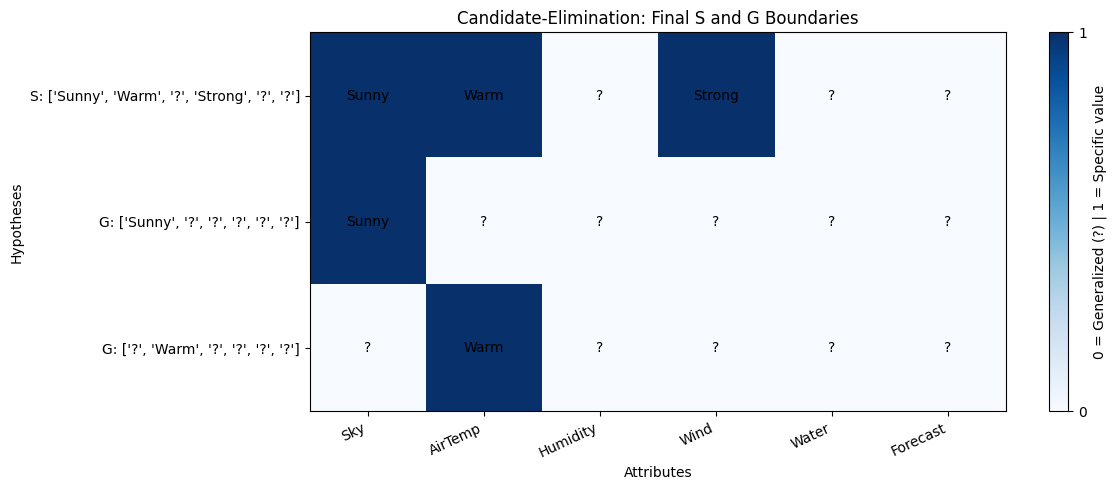


Result:
Candidate-Elimination was executed using CSV training data.
The final specific and general boundaries are displayed above.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------
# 1. Create training dataset and save as CSV
# -------------------------------------------------

columns = [
    "Sky", "AirTemp", "Humidity",
    "Wind", "Water", "Forecast", "EnjoySport"
]

data = [
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High",   "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High",   "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High",   "Strong", "Cool", "Change", "Yes"]
]

df = pd.DataFrame(data, columns=columns)
df.to_csv("training_data.csv", index=False)

# Read data from CSV
df = pd.read_csv("training_data.csv")

attributes = columns[:-1]
X = df[attributes].values.tolist()
y = df["EnjoySport"].tolist()

# Attribute domains, obtained from the dataset
domains = [
    sorted(df[attr].unique().tolist())
    for attr in attributes
]

n = len(attributes)

# -------------------------------------------------
# 2. Hypothesis functions
# -------------------------------------------------

def covers(h, x):
    return all(
        h[j] == "?" or h[j] == x[j]
        for j in range(n)
    )

def more_general(h1, h2):
    """True if h1 is at least as general as h2."""
    return all(
        b == "0" or a == "?" or a == b
        for a, b in zip(h1, h2)
    )

def remove_duplicates(hypotheses):
    result = []
    for h in hypotheses:
        if h not in result:
            result.append(h)
    return result

def minimal_generalizations(h, x):
    new_h = h.copy()

    for j in range(n):
        if new_h[j] == "0":
            new_h[j] = x[j]
        elif new_h[j] != x[j]:
            new_h[j] = "?"

    return [new_h]

def minimal_specializations(h, x, S):
    results = []

    for j in range(n):
        if h[j] == "?":
            for value in domains[j]:
                if value != x[j]:
                    candidate = h.copy()
                    candidate[j] = value

                    # Keep candidates at least as general
                    # as one hypothesis in S.
                    if any(
                        more_general(candidate, s)
                        for s in S
                    ):
                        results.append(candidate)

    return remove_duplicates(results)

def prune_G(G):
    result = []

    for g in G:
        # Remove g if another hypothesis is strictly
        # more specific than g.
        dominated = any(
            g != other and more_general(g, other)
            for other in G
        )

        if not dominated:
            result.append(g)

    return remove_duplicates(result)

def prune_S(S, G):
    return remove_duplicates([
        s for s in S
        if any(more_general(g, s) for g in G)
    ])

# -------------------------------------------------
# 3. Candidate-Elimination algorithm
# -------------------------------------------------

S = [["0"] * n]
G = [["?"] * n]

history = []

print("TRAINING DATA")
print(df.to_string(index=False))

for i, (x, label) in enumerate(zip(X, y), start=1):

    if label == "Yes":
        # Remove general hypotheses that do not cover x
        G = [g for g in G if covers(g, x)]

        # Generalize inconsistent specific hypotheses
        new_S = []

        for s in S:
            if covers(s, x):
                new_S.append(s)
            else:
                new_S.extend(minimal_generalizations(s, x))

        S = remove_duplicates(new_S)
        S = prune_S(S, G)

    else:
        # Remove specific hypotheses covering negative x
        S = [s for s in S if not covers(s, x)]

        # Specialize general hypotheses covering negative x
        new_G = []

        for g in G:
            if covers(g, x):
                new_G.extend(
                    minimal_specializations(g, x, S)
                )
            else:
                new_G.append(g)

        G = prune_G(remove_duplicates(new_G))
        G = [
            g for g in G
            if any(more_general(g, s) for s in S)
        ]

    history.append((i, [h.copy() for h in S],
                    [h.copy() for h in G]))

    print(f"\nAfter example {i} ({label}):")
    print("S =", S)
    print("G =", G)

# -------------------------------------------------
# 4. Display final boundaries
# -------------------------------------------------

print("\n" + "=" * 50)
print("FINAL SPECIFIC BOUNDARY (S)")
for h in S:
    print(h)

print("\nFINAL GENERAL BOUNDARY (G)")
for h in G:
    print(h)

# -------------------------------------------------
# 5. Plot final boundaries
# 0 = wildcard '?'
# 1 = specific attribute value
# -------------------------------------------------

all_hypotheses = [("S", h) for h in S]
all_hypotheses += [("G", h) for h in G]

matrix = np.array([
    [0 if value in ("?", "0") else 1 for value in h]
    for _, h in all_hypotheses
])

row_labels = [
    f"{boundary}: {h}"
    for boundary, h in all_hypotheses
]

fig, ax = plt.subplots(figsize=(12, 5))

im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1,
               aspect="auto")

ax.set_xticks(range(n))
ax.set_xticklabels(attributes, rotation=25, ha="right")
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        label = all_hypotheses[i][1][j]
        ax.text(j, i, label, ha="center", va="center",
                color="black", fontsize=10)

ax.set_title("Candidate-Elimination: Final S and G Boundaries")
ax.set_xlabel("Attributes")
ax.set_ylabel("Hypotheses")

plt.colorbar(im, ax=ax, ticks=[0, 1],
             label="0 = Generalized (?) | 1 = Specific value")

plt.tight_layout()
plt.show()

# -------------------------------------------------
# 6. Result
# -------------------------------------------------

print("\nResult:")
print("Candidate-Elimination was executed using CSV training data.")
print("The final specific and general boundaries are displayed above.")



# MLA02 – Fundamentals of Machine Learning

## Experiment 2: Candidate-Elimination Algorithm

### Aim
To implement the Candidate-Elimination algorithm using training examples stored in a CSV file and find the specific and general boundaries of the version space.

### Algorithm
1. Load the training dataset from a CSV file.
2. Initialize the specific boundary S and general boundary G.
3. For a positive example, generalize S and remove inconsistent hypotheses from G.
4. For a negative example, specialize G and remove inconsistent hypotheses from S.
5. Display S and G after processing the training examples.
6. Plot the final hypothesis boundaries.
